# États s, d, t : molécules de ChEMBL et leurs systèmes π

Point de départ pour réécrire les règles de newmut : comment les atomes se répartissent entre les états **s** (que
des simples), **d** (au moins une double) et **t** (au moins une triple), dans les vraies molécules et dans leurs
systèmes π.

**Molécules** : les **1 163 333** molécules de ChEMBL 34 qui n'ont que des atomes C, N, O, F, B (et H), en un seul
fragment et sans atome chargé (`donnees/chembl34_CNOFSB.tsv`, extrait de `chembl_34_chemreps.txt` sur le serveur le
2026-10-20 : sur 2 409 270 molécules, écartées 114 333 à plusieurs fragments, 508 299 avec un autre élément que
C N O F S B, 2 SMILES illisibles, puis 97 590 avec un atome chargé, groupe nitro `[N+](=O)[O-]` compris, puis
525 713 avec un S). Le nom du fichier garde le S de l'extraction de départ.

**État** : lu sur la structure de Kekulé (comme `_tag` de `evomol/newmut/matrix_rules.py`, ici pour tous les
éléments) ; un C aromatique est donc « d ». Les H explicites (dont [2H]) ne comptent pas comme atomes lourds.

**Systèmes π** : définition de `evomol/evaluation/pi_systems.py` (celle du plus grand système π des marches) :
atome π = aromatique ou hybridé SP2 / SP selon RDKit (un O de phénol, un N d'amide ou de pyrrole sont π) ; système
π = composante connexe de ces atomes. On les prend **tous**, d'au moins `TAILLE_MIN` atomes, pas seulement le plus
grand. Chaque système est écrit comme le fragment de ses seuls atomes π et des liaisons entre eux : **les
substituants sont perdus** (les atomes qui les portaient prennent des H, un N-méthylpyrrole donne un pyrrole), ce
qui permet de retrouver le même système π dans des molécules différentes. Les systèmes distincts (sans doublons)
sont écrits dans `donnees/systemes_pi_chembl34.tsv`.

Code : `etats_chembl.py` (états s, d, t) et `systemes_pi.py` (systèmes π).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "evomol").is_dir())
sys.path.insert(0, str(ROOT / "teste_newmut_V2" / "ChEMBL_comparaison"))

import pandas as pd
from IPython.display import display

import etats_chembl as ec                # teste_newmut_V2/ChEMBL_comparaison/etats_chembl.py
import systemes_pi as sp                 # teste_newmut_V2/ChEMBL_comparaison/systemes_pi.py

pd.set_option("display.float_format", "{:.2f}".format)
N_COEURS = 7      # 1 : un seul ; -1 : tous (même résultat)

## 1. Molécules : états s, d, t

Une passe sur les 1,16 million de molécules (~2 min sur 7 cœurs la première fois), en cache dans
`resultats/` (refait si le fichier de données change, ou avec `REFAIRE = True`) :
- `PAR_MOLECULE` : une ligne par molécule, nombre d'atomes lourds et d'atomes de chaque élément × état (`Cs`, `Cd`…) ;
- `CONTEXTES` : nombre d'atomes par élément, état, voisins lourds, H, charge, cycle, aromatique, nombre de doubles.

In [2]:
SANS_CHARGES = True   # écarte les molécules avec un atome chargé, nitro compris (déjà fait dans le .tsv)
REFAIRE = False

CHEMBL = ec.load_chembl()
PAR_MOLECULE, CONTEXTES = ec.compute(CHEMBL, n_jobs=N_COEURS, sans_charges=SANS_CHARGES, refaire=REFAIRE)
NB = ec.nombre_par_molecule(PAR_MOLECULE)
print(f"{len(PAR_MOLECULE)} molécules, {int(PAR_MOLECULE['n_lourds'].sum())} atomes lourds")

1163333 molécules, 35338861 atomes lourds


## 2. Extraction des systèmes π

Tous les systèmes π d'au moins `TAILLE_MIN` atomes de chaque molécule (~2-3 min sur 7 cœurs la première fois).
- `SYSTEMES` : un système distinct par ligne, écrit dans `donnees/systemes_pi_chembl34.tsv` : `smiles_pi`, `taille`
  (atomes lourds), `occurrences` (nombre de fois rencontré), `molecules` (molécules qui le contiennent), `exemple`
  (un chembl_id) ;
- `PI_MOLECULE` : par molécule, `n_systemes`, `plus_grand`, `atomes_pi` (atomes dans ses systèmes π ≥ `TAILLE_MIN`).

Puis les états s, d, t des atomes des systèmes distincts, comme pour les molécules (`PAR_PI`, `CONTEXTES_PI`).

In [3]:
TAILLE_MIN = 4

SYSTEMES, PI_MOLECULE = sp.extract(CHEMBL, taille_min=TAILLE_MIN, n_jobs=N_COEURS, refaire=REFAIRE)
assert not SYSTEMES["smiles_pi"].duplicated().any()
assert SYSTEMES["occurrences"].sum() <= PI_MOLECULE["n_systemes"].sum()
print(f"{int(PI_MOLECULE['n_systemes'].sum())} systèmes π d'au moins {TAILLE_MIN} atomes dans "
      f"{int((PI_MOLECULE['n_systemes'] > 0).sum())} molécules ; {len(SYSTEMES)} distincts → {sp.PI_TSV}")

PAR_PI, CONTEXTES_PI = ec.compute(SYSTEMES, n_jobs=N_COEURS, path=sp.PI_TSV, refaire=REFAIRE,
                                  id_col="smiles_pi", smiles_col="smiles_pi")
NB_PI = ec.nombre_par_molecule(PAR_PI)
display(SYSTEMES.head(10))

1877393 systèmes π d'au moins 4 atomes dans 1112664 molécules ; 148760 distincts → /Users/LeaClautour/Desktop/RevoMol/teste_newmut_V2/ChEMBL_comparaison/donnees/systemes_pi_chembl34.tsv


,smiles_pi,taille,occurrences,molecules,exemple
0,c1ccccc1,6,290972,236089,CHEMBL440245
1,Oc1ccccc1,7,108286,99385,CHEMBL503634
2,Oc1ccccc1O,8,37346,34554,CHEMBL501943
3,NC(=O)O,4,34384,31274,CHEMBL503870
4,c1ccncc1,6,31293,30295,CHEMBL217730
5,c1ccc2[nH]ccc2c1,9,31323,27480,CHEMBL500704
6,O=CNc1ccccc1,9,26159,25386,CHEMBL500246
7,Nc1ccccc1,7,24617,23941,CHEMBL264472
8,NC(=O)c1ccccc1,9,24081,23484,CHEMBL409812
9,c1c[nH]cn1,5,22725,21357,CHEMBL440245


## 3. Atomes pontés selon la taille du plus grand cycle

Têtes de pont comptées par RDKit (`rdMolDescriptors.CalcNumBridgeheadAtoms`, comme `num_bridgehead_atoms` de
`teste_newmut_V1/pontage_smiles.ipynb`) : atomes communs à deux cycles qui partagent au moins deux liaisons
(norbornane : 2 ; cycles accolés comme le naphtalène, ou spiro : 0). Plus grand cycle : parmi les cycles minimaux
(SSSR) de RDKit, 0 sans cycle, `MAX_CYCLE` et plus regroupés. Sur les molécules et sur les systèmes π distincts
(~1 min la première fois, en cache dans `resultats/`).

Colonnes : nombre d'objets, têtes de pont (total, moyenne par objet, % des atomes lourds), part des objets qui en ont
au moins une, puis nombre d'objets à 1, 2, 3, ≥ 4 têtes de pont.

molécules


,objets,têtes de pont,moyenne,% des atomes,% avec ≥ 1,1,2,3,≥ 4
plus grand cycle,,,,,,,,,
0,12031,0,0.00,0.00,0.00,0,0,0,0
3,984,0,0.00,0.00,0.00,0,0,0,0
4,727,22,0.03,0.17,1.51,0,11,0,0
5,25233,3024,0.12,0.46,5.33,0,1212,0,133
6,1037002,109653,0.11,0.36,4.03,0,30340,86,11378
7,50463,16237,0.32,1.08,13.33,0,5367,201,1157
8,7059,6275,0.89,2.13,39.30,0,2531,8,235
9,1746,1739,1.00,2.31,47.71,0,795,3,35
10,1838,610,0.33,1.13,15.07,0,249,0,28


systèmes π distincts


,objets,têtes de pont,moyenne,% des atomes,% avec ≥ 1,1,2,3,≥ 4
plus grand cycle,,,,,,,,,
0,1766,0,0.00,0.00,0.00,0,0,0,0
3,2,0,0.00,0.00,0.00,0,0,0,0
4,16,0,0.00,0.00,0.00,0,0,0,0
5,2904,0,0.00,0.00,0.00,0,0,0,0
6,142645,0,0.00,0.00,0.00,0,0,0,0
7,1095,2,0.00,0.01,0.09,0,1,0,0
8,29,0,0.00,0.00,0.00,0,0,0,0
9,6,0,0.00,0.00,0.00,0,0,0,0
10,5,0,0.00,0.00,0.00,0,0,0,0


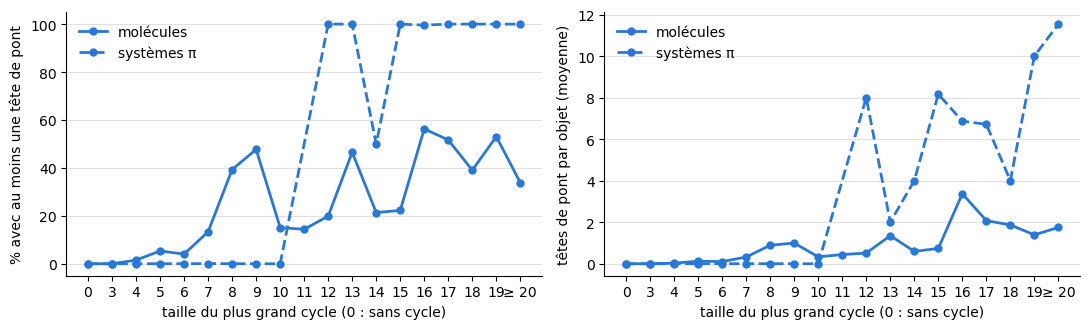

In [4]:
MAX_CYCLE = 20

PONTS = sp.compute_ponts(CHEMBL, "canonical_smiles", ec.DATA, n_jobs=N_COEURS, refaire=REFAIRE)
PONTS_PI = sp.compute_ponts(SYSTEMES, "smiles_pi", sp.PI_TSV, n_jobs=N_COEURS, refaire=REFAIRE)
PONTS_CYCLE = sp.ponts_par_cycle(PONTS, MAX_CYCLE)
PONTS_CYCLE_PI = sp.ponts_par_cycle(PONTS_PI, MAX_CYCLE)
print("molécules"); display(PONTS_CYCLE)
print("systèmes π distincts"); display(PONTS_CYCLE_PI)
sp.plot_ponts(PONTS_CYCLE, PONTS_CYCLE_PI);

### Voir les molécules ou les systèmes π selon le plus grand cycle

Choisir le jeu (molécules ou systèmes π distincts), la taille du plus grand cycle et le nombre d'exemples, puis
**Tirer** (exemples tirés au hasard ; recliquer pour en voir d'autres). En bleu : le plus grand cycle (tous ceux de
cette taille s'il y en a plusieurs) ; en orange : têtes de pont. Case à cocher : seulement ceux qui ont au moins une tête de pont.
Sous chaque dessin : chembl_id (ou nombre de molécules qui contiennent le système π), plus grand cycle, têtes de pont.

In [5]:
sp.explorer(CHEMBL, PONTS, SYSTEMES, PONTS_PI)

## 4. Systèmes π par molécule

Nombre de systèmes π d'au moins `TAILLE_MIN` atomes dans chaque molécule.

,molecules,%
systèmes π,,
0,50669,4.36
1,542601,46.64
2,435087,37.40
3,101792,8.75
4,21202,1.82
5,5946,0.51
≥ 6,6036,0.52


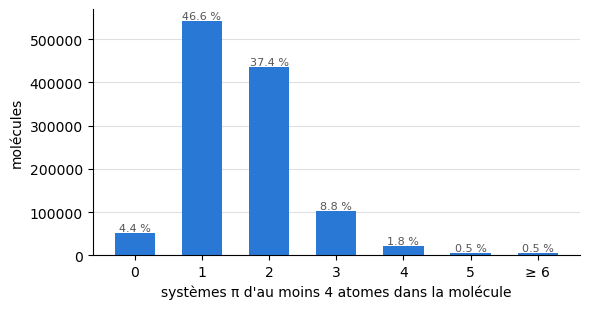

In [6]:
PAR_NOMBRE = sp.systemes_par_molecule(PI_MOLECULE)
display(PAR_NOMBRE)
sp.plot_systemes_par_molecule(PAR_NOMBRE);

## 5. Nombre d'atomes des systèmes π

Taille (atomes lourds) des systèmes π : sur les systèmes distincts (chaque SMILES une fois), sur toutes les
occurrences (chaque système autant de fois qu'on le rencontre), et pour le plus grand système de chaque molécule ;
part des atomes de la molécule qui sont dans un système π ≥ `TAILLE_MIN`. Puis la taille du plus grand système selon
celle de la molécule, et la composition des systèmes distincts par élément.

,count,mean,std,min,5%,25%,50%,75%,95%,max
taille (systèmes distincts),148760.00,20.46,6.04,4.00,11.00,16.00,20.00,24.00,31.00,144.00
taille (toutes les occurrences),1877393.00,10.71,6.04,4.00,4.00,6.00,9.00,14.00,23.00,144.00
plus grand système par molécule,1112664.00,13.48,6.28,4.00,6.00,9.00,12.00,17.00,25.00,144.00
% des atomes dans un système π,1163333.00,60.23,24.22,0.00,10.81,46.34,64.00,78.26,93.55,100.00


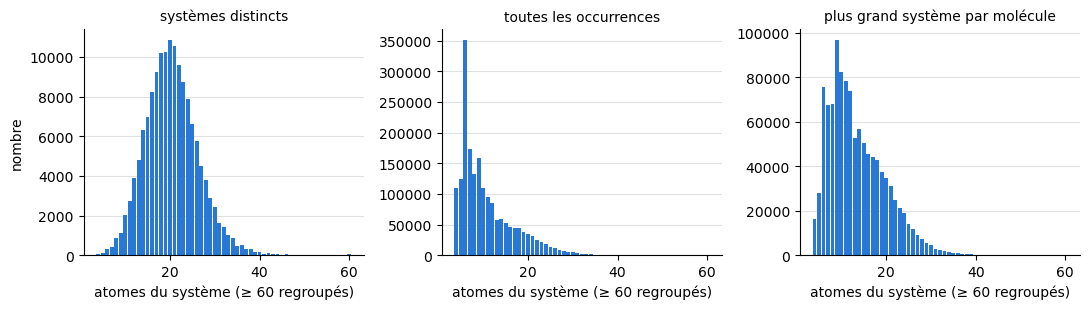

In [7]:
display(sp.resume_tailles(SYSTEMES, PI_MOLECULE))
sp.plot_tailles(SYSTEMES, PI_MOLECULE);

,atomes,% des atomes,% des systèmes qui en ont
element,,,
C,2231719,73.31,100.00
N,470916,15.47,91.84
O,341218,11.21,88.58
B,445,0.01,0.29


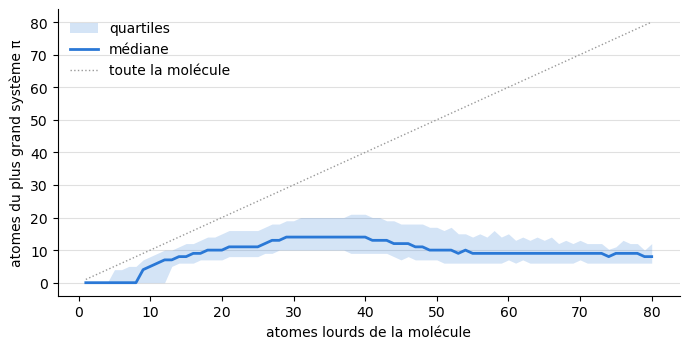

In [8]:
sp.plot_plus_grand_vs_taille(PI_MOLECULE);
display(sp.composition(PAR_PI))

## 6. États s, d, t : molécules contre systèmes π

Part de s, d, t dans chaque élément, pour les atomes des molécules et pour ceux des systèmes π distincts, côte à côte,
avec l'écart (points de %, systèmes π moins molécules). Un atome s dans un système π est un atome π sans liaison
multiple : O de phénol ou d'ester, N d'amide, d'aniline ou de pyrrole…

molécules                      systèmes π                        \
etat          % s   % d  % t     total        % s   % d  % t      total   
element                                                                   
C           40.21 59.39 0.40  26738725       0.00 99.17 0.83 2231719.00   
N           68.21 30.21 1.58   4014518      51.18 46.16 2.65  470916.00   
O           53.11 46.89 0.00   4067773      54.61 45.39 0.00  341218.00   
F          100.00  0.00 0.00    514704        NaN   NaN  NaN        NaN   
B           99.94  0.06 0.00      3141      99.78  0.22 0.00     445.00   
tous        45.75 53.76 0.48  35338861      14.05 84.93 1.02 3044298.00   

         écart             
etat       % s   % d  % t  
element                    
C       -40.21 39.78 0.43  
N       -17.03 15.95 1.08  
O         1.50 -1.50 0.00  
F          NaN   NaN  NaN  
B        -0.16  0.16 0.00  
tous    -31.70 31.16 0.54

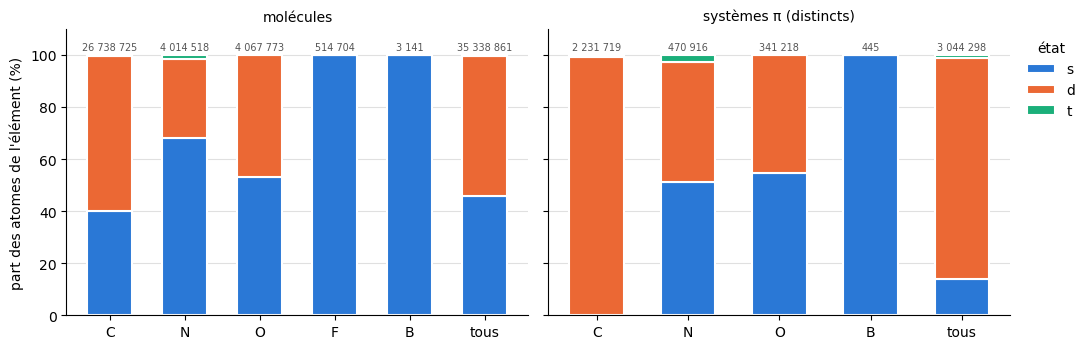

In [9]:
PAR_ETAT = ec.atomes_par_etat(CONTEXTES)
PAR_ETAT_PI = ec.atomes_par_etat(CONTEXTES_PI)
display(ec.compare_par_etat(PAR_ETAT, PAR_ETAT_PI))
ec.plot_compare_etats(PAR_ETAT, PAR_ETAT_PI);

Nombre et part des atomes s, d, t par objet (une molécule, ou un système π distinct).

count  mean   std  min    5%   25%   50%   75%   95%  \
molécules  n_lourds 1163333.00 30.38 17.33 1.00 16.00 23.00 27.00 33.00 51.00   
           s        1163333.00 13.90 11.97 0.00  4.00  8.00 12.00 16.00 31.00   
           d        1163333.00 16.33  8.71 0.00  6.00 12.00 16.00 20.00 28.00   
           t        1163333.00  0.15  0.57 0.00  0.00  0.00  0.00  0.00  2.00   
           % s      1163333.00 44.26 18.00 0.00 17.24 31.25 42.86 55.10 77.14   
           % d      1163333.00 55.18 17.94 0.00 22.22 44.44 56.82 66.67 82.35   
           % t      1163333.00  0.56  2.34 0.00  0.00  0.00  0.00  0.00  6.06   
systèmes π n_lourds  148760.00 20.46  6.04 4.00 11.00 16.00 20.00 24.00 31.00   
           s         148760.00  2.88  1.33 0.00  1.00  2.00  3.00  4.00  5.00   
           d         148760.00 17.38  5.57 0.00  8.00 14.00 18.00 20.00 26.00   
           t         148760.00  0.21  0.68 0.00  0.00  0.00  0.00  0.00  2.00   
           % s       148760.00 14.46  6.19 0.00  5.26 10.00 14.29 18.18 25.00   
           % d       148760.00 84.39  6.88 0.00 72.73 80.00 85.71 88.89 94.12   
           % t       148760.00  1.15  4.01 0.00  0.00  0.00  0.00  0.00 10.53   

                       max  
molécules  n_lourds 633.00  
           s        357.00  
           d        390.00  
           t         16.00  
           % s      100.00  
           % d      100.00  
           % t      100.00  
systèmes π n_lourds 144.00  
           s         26.00  
           d        118.00  
           t         12.00  
           % s       60.00  
           % d      100.00  
           % t      100.00

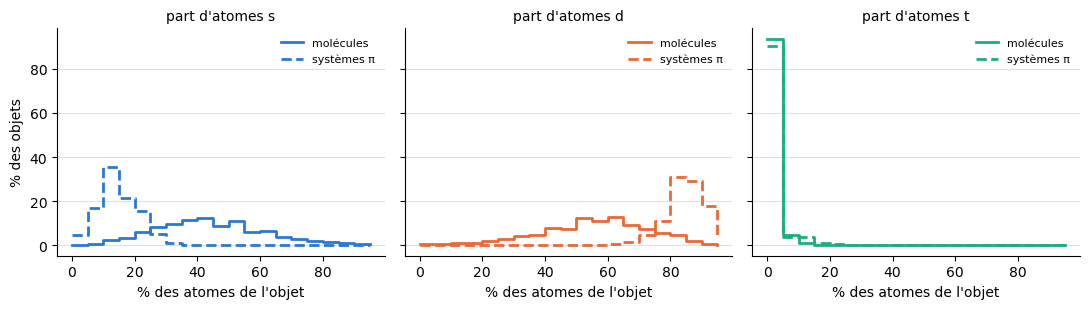

In [10]:
display(pd.concat({"molécules": ec.resume(NB), "systèmes π": ec.resume(NB_PI)}))
ec.plot_compare_distribution(NB, NB_PI);

In [11]:
print("molécules sans aucun atome s :", int((NB["s"] == 0).sum()), "· avec au moins un t :", int((NB["t"] > 0).sum()))
print("systèmes π sans aucun atome s :", int((NB_PI["s"] == 0).sum()), "sur", len(NB_PI),
      "· avec au moins un t :", int((NB_PI["t"] > 0).sum()))

molécules sans aucun atome s : 832 · avec au moins un t : 78415
systèmes π sans aucun atome s : 2319 sur 148760 · avec au moins un t : 14128


Molécules et systèmes π qui ont au moins un atome de chaque élément × état.

In [12]:
display(pd.concat({"molécules": ec.molecules_avec(PAR_MOLECULE), "systèmes π": ec.molecules_avec(PAR_PI)}, axis=1))

molécules                                      systèmes π            \
         molecules                         %             molecules             
etat             d          s        t     d     s    t          d         s   
element                                                                        
C       1155059.00 1135942.00 78414.00 99.29 97.65 6.74  148752.00      0.00   
N        631957.00 1010676.00 58649.00 54.32 86.88 5.04  108339.00 124477.00   
O        898879.00  886963.00     0.00 77.27 76.24 0.00  103566.00  98887.00   
F             0.00  237469.00     0.00  0.00 20.41 0.00       0.00      0.00   
S             0.00       0.00     0.00  0.00  0.00 0.00       0.00      0.00   
B             1.00    3050.00     0.00  0.00  0.26 0.00       1.00    427.00   

                                   
                     %             
etat           t     d     s    t  
element                            
C       14128.00 99.99  0.00 9.50  
N       11487.00 72.83 83.68 7.72  
O           0.00 69.62 66.47 0.00  
F           0.00  0.00  0.00 0.00  
S           0.00  0.00  0.00 0.00  
B           0.00  0.00  0.29 0.00

Part moyenne des atomes s, d, t selon la taille (molécules, puis systèmes π distincts), jusqu'à `MAX_ATOMES` atomes.

molécules                      systèmes π                     
               % s   % d  % t molecules        % s   % d  % t molecules
n_lourds                                                               
1           100.00  0.00 0.00     11.00        NaN   NaN  NaN       NaN
6            66.49 29.26 4.26    282.00        NaN   NaN  NaN       NaN
11           53.39 45.57 1.04   3493.00        NaN   NaN  NaN       NaN
16           45.54 53.48 0.98  16952.00        NaN   NaN  NaN       NaN
21           42.52 56.80 0.68  45058.00        NaN   NaN  NaN       NaN
26           41.75 57.74 0.51  61911.00        NaN   NaN  NaN       NaN
31           41.80 57.67 0.53  47320.00        NaN   NaN  NaN       NaN
36           44.23 55.26 0.52  26709.00        NaN   NaN  NaN       NaN
41           47.76 51.87 0.36  11646.00        NaN   NaN  NaN       NaN
46           51.48 48.32 0.20   5894.00        NaN   NaN  NaN       NaN
51           55.71 44.14 0.15   3017.00        NaN   NaN  NaN       NaN
56           57.65 42.22 0.13   2223.00        NaN   NaN  NaN       NaN
61           58.94 40.92 0.14   1500.00        NaN   NaN  NaN       NaN
66           60.00 39.88 0.12   1205.00        NaN   NaN  NaN       NaN
71           60.85 39.03 0.12    753.00        NaN   NaN  NaN       NaN
76           61.14 38.75 0.11    676.00        NaN   NaN  NaN       NaN
4              NaN   NaN  NaN       NaN      30.65 60.48 8.87     62.00
9              NaN   NaN  NaN       NaN      19.77 76.91 3.32   1112.00
14             NaN   NaN  NaN       NaN      15.76 82.82 1.42   6337.00
19             NaN   NaN  NaN       NaN      14.18 84.70 1.12  10267.00
24             NaN   NaN  NaN       NaN      13.22 85.92 0.86   7855.00
29             NaN   NaN  NaN       NaN      12.94 86.27 0.79   2871.00
34             NaN   NaN  NaN       NaN      12.96 86.51 0.53    844.00
39             NaN   NaN  NaN       NaN      12.95 86.88 0.16    156.00
44             NaN   NaN  NaN       NaN      13.93 85.78 0.29     47.00
49             NaN   NaN  NaN       NaN       8.30 91.70 0.00     15.00
54             NaN   NaN  NaN       NaN      13.25 86.32 0.43     26.00
60             NaN   NaN  NaN       NaN      13.50 86.50 0.00     20.00
65             NaN   NaN  NaN       NaN      23.08 76.92 0.00      1.00
70             NaN   NaN  NaN       NaN       2.86 97.14 0.00      1.00

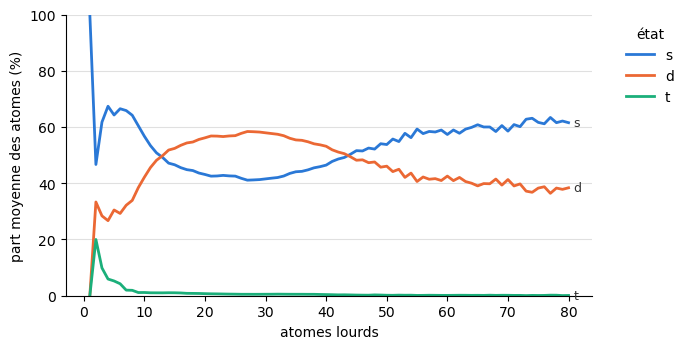

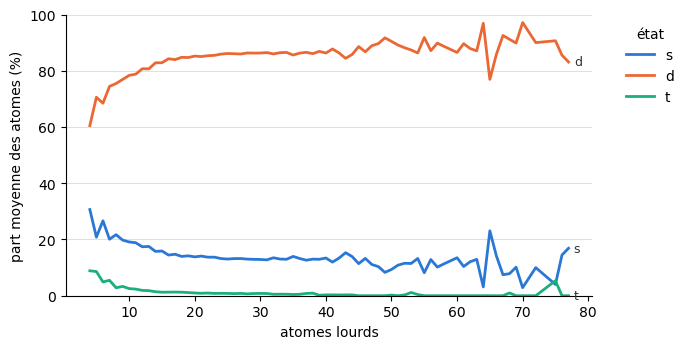

In [13]:
MAX_ATOMES = 80

PARTS_TAILLE = ec.parts_par_taille(NB, MAX_ATOMES)
PARTS_TAILLE_PI = ec.parts_par_taille(NB_PI, MAX_ATOMES)
ec.plot_parts_par_taille(PARTS_TAILLE);
ec.plot_parts_par_taille(PARTS_TAILLE_PI);
display(pd.concat({"molécules": PARTS_TAILLE.iloc[::5], "systèmes π": PARTS_TAILLE_PI.iloc[::5]}, axis=1))

## 7. Détail par contexte d'atome

Pour un élément (et un état), les atomes regroupés selon les colonnes `PAR` : `voisins` (atomes lourds), `H`,
`charge`, `cycle`, `aromatique`, `doubles` (nombre de doubles : 2 pour un C d'allène). Dans les systèmes π, voisins et
H sont ceux du fragment (substituants retirés). Ex. : C s des molécules selon le nombre de voisins lourds (C s à 4
voisins : carbones quaternaires, cf. R5) ; atomes s des systèmes π.

In [14]:
ELEMENT, ETAT = "C", "s"
PAR = ["voisins", "H"]

display(ec.contextes_de(CONTEXTES, ELEMENT, ETAT, PAR))

atomes     %
voisins H               
2       2  5694777 52.97
1       3  2414853 22.46
3       1  2086791 19.41
4       0   554860  5.16
0       0        1  0.00
        4        1  0.00
1       2        1  0.00

In [15]:
# Atomes s dans les systèmes π distincts
for e in ("N", "O", "C"):
    print(e, "s")
    display(ec.contextes_de(CONTEXTES_PI, e, "s", ["voisins", "H", "cycle", "aromatique"], top=10))

N s


atomes     %
voisins H cycle aromatique              
2       1 False False        74673 30.98
1       2 False False        64021 26.56
2       1 True  True         60487 25.09
3       0 True  True         33015 13.70
2       1 True  False         5265  2.18
3       0 True  False         1919  0.80
          False False         1655  0.69

O s


atomes     %
voisins H cycle aromatique              
1       1 False False       142315 76.37
2       0 True  True         27276 14.64
          False False        15044  8.07
          True  False         1721  0.92

C s


,,,,atomes,%
voisins,H,cycle,aromatique,,


In [16]:
# Atomes à deux doubles ou plus, par élément et état
display(CONTEXTES[CONTEXTES["doubles"] >= 2].groupby(["element", "etat", "doubles"])["atomes"].sum().to_frame())

,,,atomes
element,etat,doubles,
C,d,2,220


## 8. Systèmes π les plus fréquents

Les 30 systèmes π distincts présents dans le plus de molécules, et le dessin des 20 premiers (nombre de molécules ·
atomes).

,smiles_pi,taille,occurrences,molecules,exemple
0,c1ccccc1,6,290972,236089,CHEMBL440245
1,Oc1ccccc1,7,108286,99385,CHEMBL503634
2,Oc1ccccc1O,8,37346,34554,CHEMBL501943
3,NC(=O)O,4,34384,31274,CHEMBL503870
4,c1ccncc1,6,31293,30295,CHEMBL217730
5,c1ccc2[nH]ccc2c1,9,31323,27480,CHEMBL500704
6,O=CNc1ccccc1,9,26159,25386,CHEMBL500246
7,Nc1ccccc1,7,24617,23941,CHEMBL264472
8,NC(=O)c1ccccc1,9,24081,23484,CHEMBL409812
9,c1c[nH]cn1,5,22725,21357,CHEMBL440245


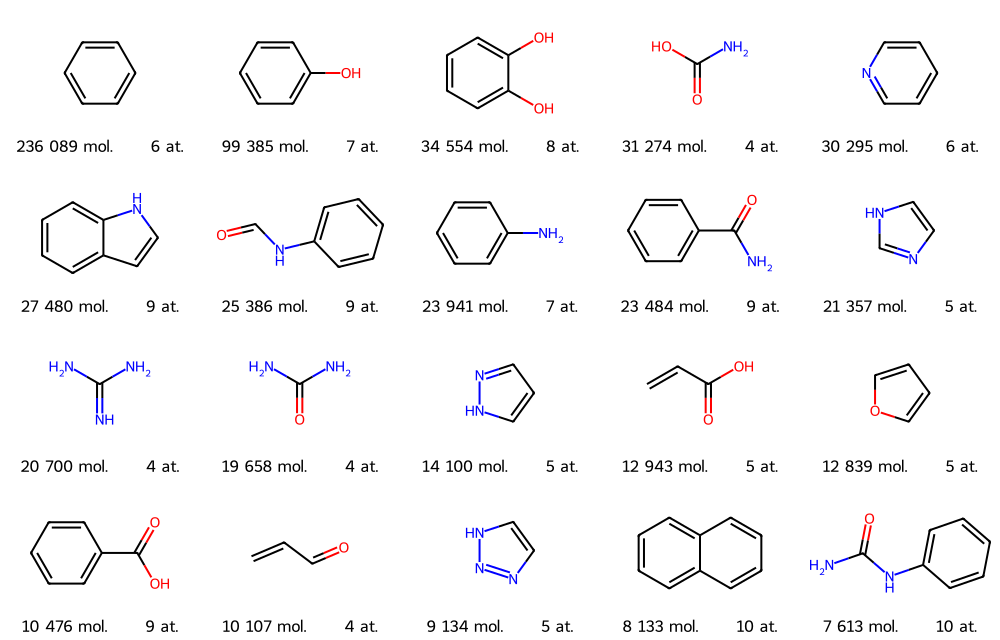

In [17]:
display(SYSTEMES.head(30))
sp.draw_frequents(SYSTEMES, 20)

## 9. Systèmes π avec des C sp3 enclos

Un C qui n'est pas π (sp3) est ajouté à un système π si **au moins deux** de ses voisins lourds sont des atomes de ce
même système : C9 du fluorène et du 9,9-diméthylfluorène, CH2 du cyclopentadiène, de l'indane-1,3-dione… Il peut porter
d'autres substituants non π, perdus dans le fragment (comme pour les autres atomes). Le CH2 du diphénylméthane ou du
9,10-dihydroanthracène relie deux systèmes différents (un voisin dans chacun) et n'est pas ajouté.

On garde les systèmes π distincts qui ont au moins un C sp3 enclos, et on en tire `N_SP3` au hasard (`GRAINE`),
écrits dans `donnees/systemes_pi_sp3_chembl34.tsv` (`h_sp3` : H de chaque C sp3 dans le fragment ;
`h_sp3_molecules` : H de ces C dans les molécules, « H:nombre », sur toutes les occurrences). ~3 min la première fois.

Histogramme du nombre de H sur ces C sp3 : dans les fragments (substituants retirés, remplacés par des H) et dans les
molécules d'où ils viennent.

15648 systèmes π avec C sp3 enclos → /Users/LeaClautour/Desktop/RevoMol/teste_newmut_V2/ChEMBL_comparaison/donnees/systemes_pi_sp3_chembl34.tsv


,fragments,molécules,% fragments,% molécules
H sur le C sp3,,,,
0,3,29365,0.02,28.83
1,438,29615,2.63,29.07
2,16238,42879,97.36,42.10


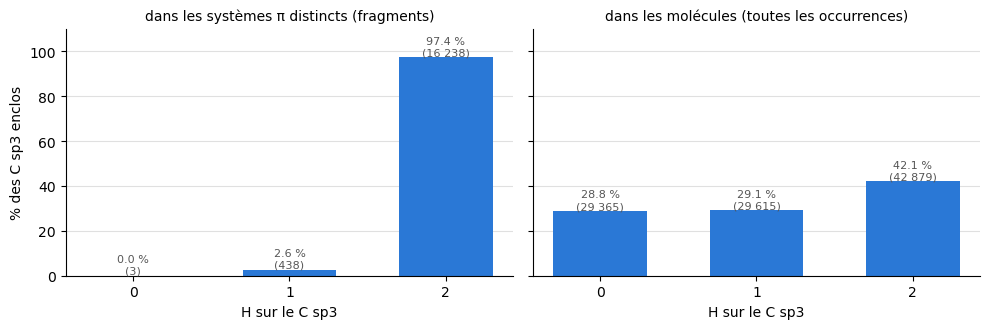

In [18]:
N_SP3, GRAINE = 20000, 0

SYSTEMES_SP3 = sp.extract_sp3(CHEMBL, n=N_SP3, graine=GRAINE, taille_min=TAILLE_MIN, n_jobs=N_COEURS, refaire=REFAIRE)
H_SP3 = sp.h_sp3_comptes(SYSTEMES_SP3)
print(f"{len(SYSTEMES_SP3)} systèmes π avec C sp3 enclos → {sp.PI_SP3_TSV}")
display(H_SP3)
sp.plot_h_sp3(H_SP3);

Fragments (systèmes π avec C sp3 enclos, tirés au hasard) dont un C sp3 porte 0 H, 1 H, puis 2 H dans le fragment ;
ces C sont en orange, et sous chaque fragment le nombre de molécules qui le contiennent. `N_EXEMPLES` fragments par
cas, `GRAINE_EXEMPLES` pour en voir d'autres.

C sp3 enclos avec 0 H
3 fragments sur 3


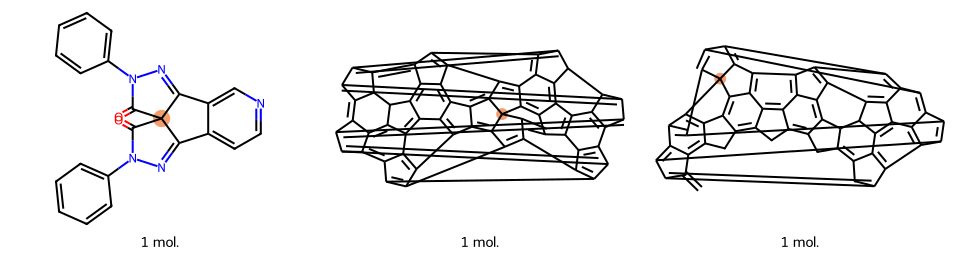

C sp3 enclos avec 1 H
20 fragments sur 360


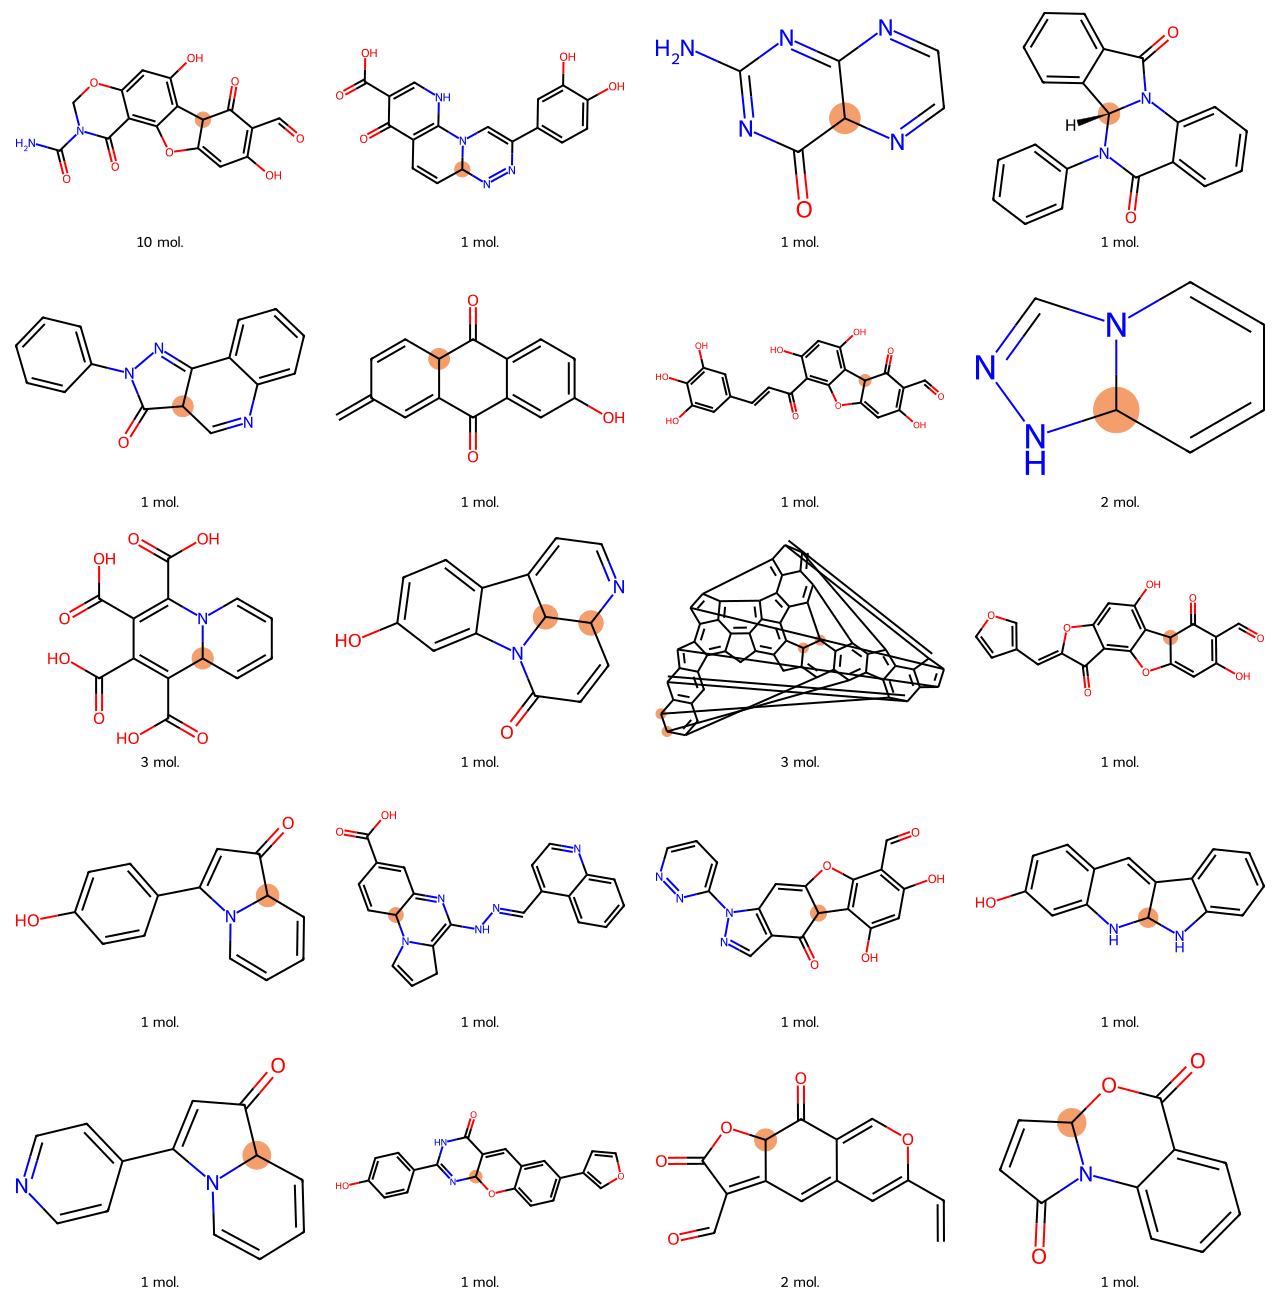

In [19]:
N_EXEMPLES, GRAINE_EXEMPLES = 20, 0

for h in (0, 1):
    print(f"C sp3 enclos avec {h} H")
    display(sp.exemples_h_sp3(SYSTEMES_SP3, h, N_EXEMPLES, GRAINE_EXEMPLES))

,smiles_pi,taille,n_sp3,h_sp3,occurrences,molecules,exemple,h_sp3_molecules
0,c1ccc2c(c1)OCO2,9,1,2,8728,8462,CHEMBL503644,"0:130,1:14,2:8584"
1,O=C1CNC(=O)N1,7,1,2,5152,5112,CHEMBL1078396,"0:3820,1:1048,2:284"
2,O=C1C=CCO1,6,1,2,2881,2829,CHEMBL505936,"0:491,1:1298,2:1092"
3,O=C1Cc2ccccc2N1,10,1,2,2882,2779,CHEMBL500246,"0:2424,1:255,2:203"
4,O=C1NCc2ccccc21,10,1,2,1347,1346,CHEMBL8933,"0:368,1:364,2:615"
5,O=C1CC(=O)NC(=O)N1,9,1,2,1139,1118,CHEMBL7413,"0:816,1:268,2:55"
6,O=C1C=CCC=C1,7,1,2,1070,1054,CHEMBL8313,"0:1067,1:3"
7,c1ccc2c(c1)Cc1ccccc1-2,13,1,2,1049,1025,CHEMBL500357,"0:160,1:805,2:84"
8,O=C1COc2ccccc2N1,11,1,2,979,979,CHEMBL12366,"0:21,1:375,2:583"
9,O=C1CN=C(c2ccccc2)c2ccccc2N1,18,1,2,815,814,CHEMBL501238,"1:744,2:71"


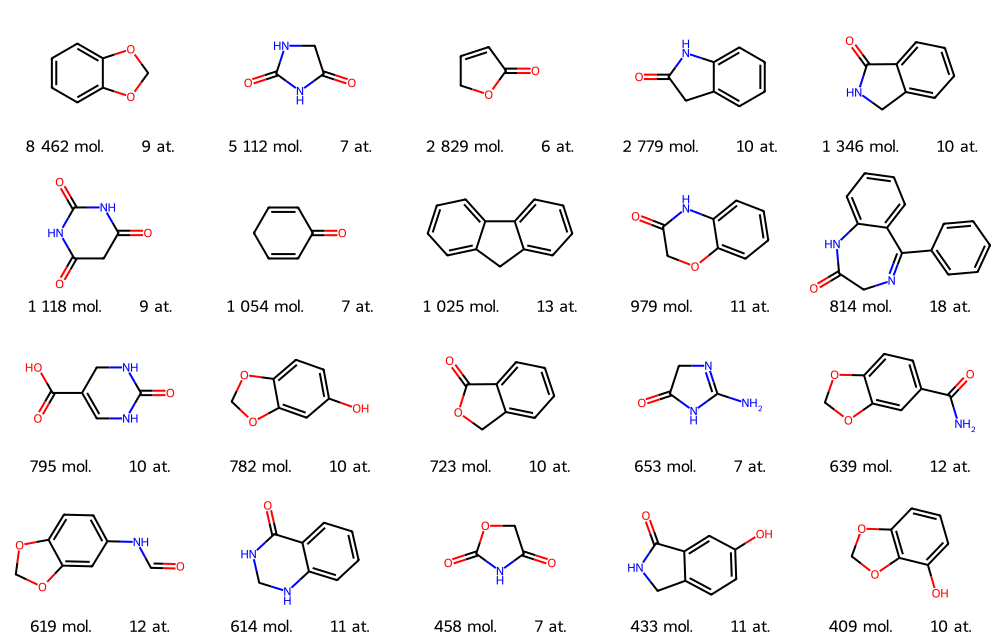

In [20]:
display(SYSTEMES_SP3.head(20))
sp.draw_frequents(SYSTEMES_SP3, 20)